# Figure 1: exact peptide lookup selects compact search databases

Panel a is a schematic of the database strategies and of one worked healthy-stool acquisition; it ships as artwork and its typed numbers are recomputed here. Panels b to e are regenerated from `source_data/Fig1/` with the plot code of the original producers and compared pixel by pixel with the panels those producers rendered. The text statistics of Results lines 51 to 65 are recomputed in the last cell.

Run from the repository root: `python paper.py build Fig1`.

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()

In [2]:
D = panels.load(SD)

## Panel a

Schematic (v30). Human proteomics, conventional metaproteomics and FastaLake, with the worked acquisition `20181231_QX7_PhGe_LC95_SA_WorkflowReplicates_2` and its composition-matched scrambled control (seed 20260901). Supports "FastaLake pools de novo peptide queries from the 58 healthy-stool acquisitions ... shown for one acquisition" (legend, v28d line 71) and Results line 53. n: one acquisition; the study-level lookup pools 58 acquisitions. No test. The FastaLake column (one funnel: reservoir, exact match to study-supported proteins, per-acquisition match, parsimony) is rebuilt by `artwork/build_fig1a_funnel.py` in the last cell and compared with `expected/Fig1_v30.png`. Every typed number is recomputed below and traced in `ARTWORK_NUMBERS.md`.

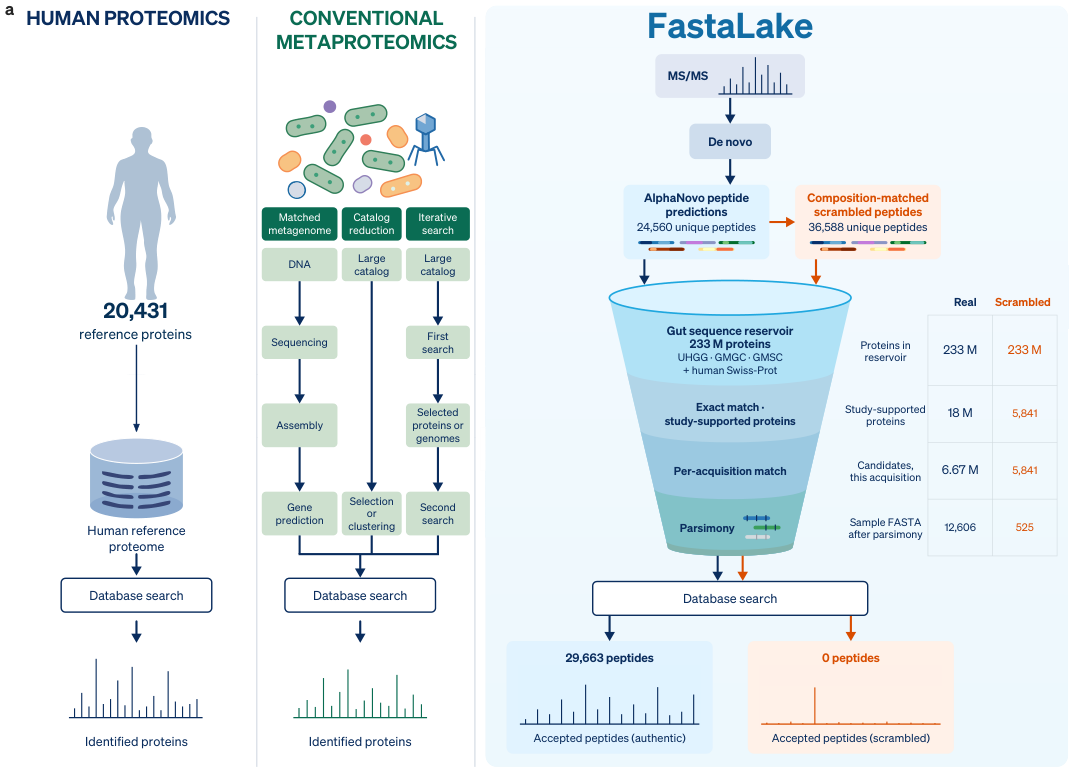

In [3]:
panels.show(panels.panel_a(UNIT, OUT))

In [4]:
for k, v in panels.artwork_numbers(D).items():
    print(f"{k:60s} {v}")

20,431 reference proteins                                    20,431
233 M proteins (reservoir, and table Real and Scrambled)     233 M
18 M study-supported proteins (table, Real)                  18 M
5,841 study-supported proteins (table, Scrambled; v30)       5,841
24,560 unique peptides                                       24,560
36,588 unique peptides (scrambled)                           36,588
6.67 M candidates, this acquisition                          6.67 M
5,841 candidates (scrambled)                                 5,841
12,606 sample FASTA after parsimony                          12,606
525 sample FASTA (scrambled)                                 525
29,663 peptides                                              29,663
0 peptides (scrambled)                                       0


## Panel b

Entries in each acquisition-specific FASTA, by cohort; dashed line, the 20,431-entry human reference proteome. Supports "All 726 acquisition-specific databases contained fewer entries than the 20,431-entry human reference proteome, with median sizes ranging from 3,100 proteins in CAMPI to 12,200 in healthy stool" (v28d line 55). n = 726 acquisitions (15 CAMPI, 58 healthy stool, 306 PREDICT, 347 CapScan). Descriptive; bars are medians. No test.

{'n': {'CAMPI': 15, 'CapScan': 347, 'HSTOOL': 58, 'PREDICT': 306}, 'total': 726, 'median': {'CAMPI': 3057.0, 'HSTOOL': 12212.5, 'PREDICT': 7906.0, 'CapScan': 7941.0}, 'max': 16923, 'min': 241, 'n_below_human': 726, 'human_entries': 20431}


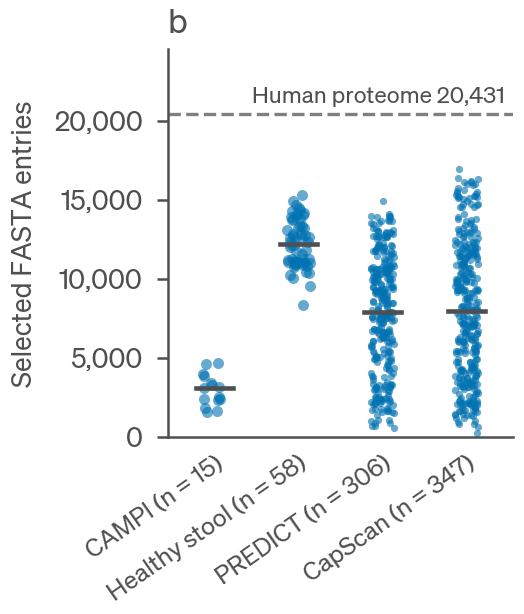

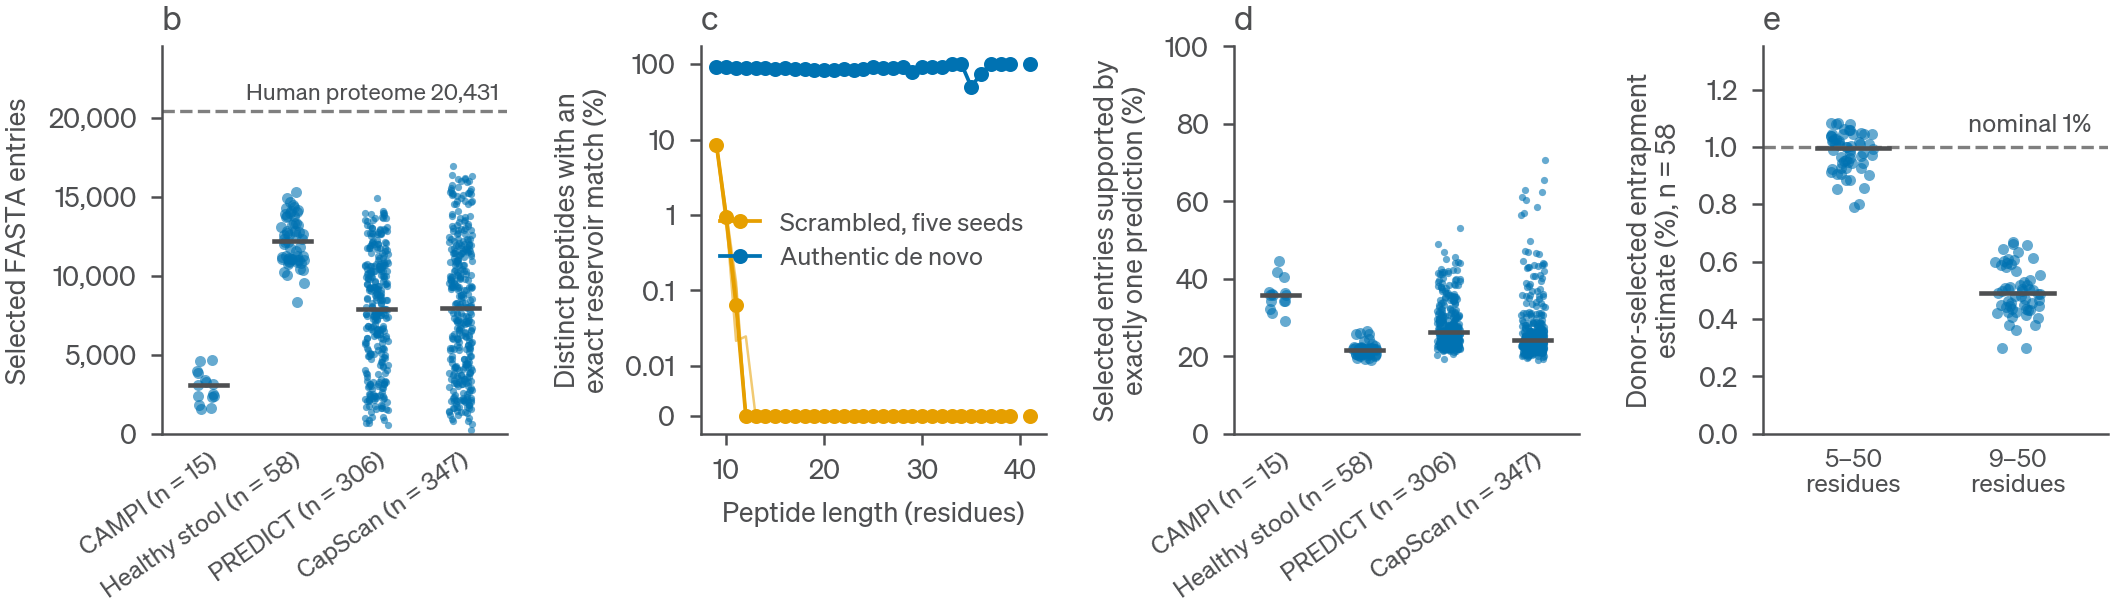

In [5]:
panels.panel_b(D, OUT)
print(panels.stat_b_sizes(D))
panels.show(OUT / "panel_b.png")

## Panel c

Fraction of distinct authentic or scrambled queries of the worked acquisition with an exact match in the 233,497,702-sequence reservoir, by peptide length; five scrambling seeds (thin lines) and their median. Supports "The fraction of scrambled queries matching a reservoir protein fell from 8.1–8.9% for nine-residue queries to 0.7–1.1% at ten residues, with no match in 86,000 query–seed evaluations at ≥13 residues" (v28d line 59). Unit: distinct query within one seed; n per seed and length in `length_by_arm.tsv`. Range over seeds; no test.

{'len9_min': 8.07609475951184, 'len9_max': 8.883704235463021, 'len9_n_per_seed': {20260901: 5571, 20260913: 5572, 20260914: 5572, 20260915: 5572, 20260916: 5572}, 'len10_min': 0.70093457943925, 'len10_max': 1.09034267912772, 'len10_n_per_seed': {20260901: 5136, 20260913: 5136, 20260914: 5136, 20260915: 5136, 20260916: 5135}, 'n_ge13': 85835, 'matches_ge13': 0, 'n_seeds': 5}


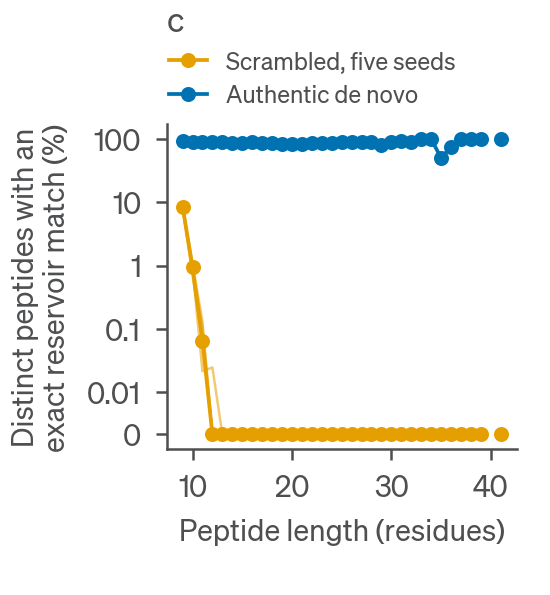

In [6]:
panels.panel_c(D, OUT)
print(panels.stat_c_scramble(D))
panels.show(OUT / "panel_c.png")

## Panel d

Per acquisition, the fraction of selected proteins that contain exactly one distinct production (top-30%) lookup query. Supports "Across cohorts, a median 21.6–35.8% of selected proteins matched only one distinct top-scoring lookup query" and "95.7–97.7% of selected proteins contained at least one qualifying prediction whose sequence the final search also identified" (v28d line 63). n = 726 acquisitions as in panel b. Bars are medians. No test. The 4,258 of 29,663 accepted peptides absent from the archived predictions (same line) is computed here too.

{'one_top': {'CAMPI': 35.81935483870967, 'CAPSCAN': 24.10980704197334, 'HSTOOL': 21.635010831243672, 'PREDICT': 26.3566316616555}, 'fl_corr': {'CAMPI': 97.67441860465115, 'CAPSCAN': 96.73081993145269, 'HSTOOL': 97.21180253497903, 'PREDICT': 95.69992687145346}, 'one_top_min': 21.635010831243672, 'one_top_max': 35.81935483870967, 'fl_corr_min': 95.69992687145346, 'fl_corr_max': 97.67441860465115}
{'accepted': 29663, 'not_predicted': 4258, 'percent': 14.354583150726494}


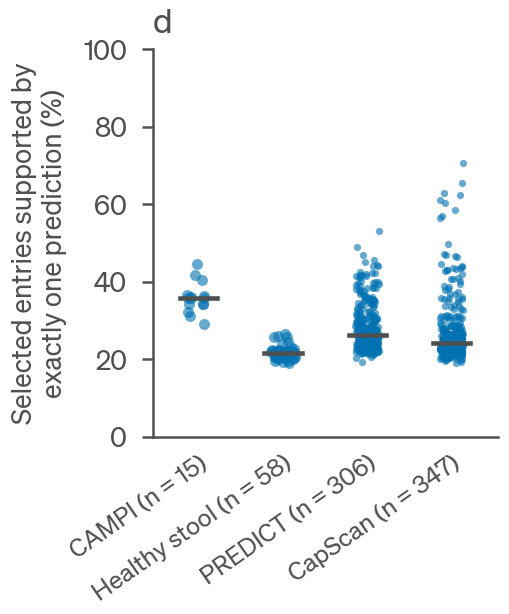

In [7]:
panels.panel_d(D, OUT)
print(panels.stat_d_support(D))
print(panels.stat_d_not_predicted(D))
panels.show(OUT / "panel_d.png")

## Panel e

Donor-selected entrapment estimates (FDRBench paired estimator) in 58 healthy-stool acquisitions, each the mean of three entrapment seeds, for accepted peptides of 5–50 and 9–50 residues at peptide q ≤ 0.01. Supports "The median paired estimate was 1.0% for accepted 5–50-residue peptides and 0.49% for the 9–50-residue subset of the same searches" (v28d line 65). Unit: acquisition, n = 58. Bars are medians. No test. The seed means are recomputed from the per-seed counts.

{'seeds': [20260910, 20260911, 20260912], 'max_abs_diff_seed_means': 9.974659986866641e-17, 'e5_n': 58, 'e5_median': 0.995814575431095, 'e5_q25': 0.94233471800066, 'e5_q75': 1.0359822913466425, 'e9_n': 58, 'e9_median': 0.48933836622050997, 'e9_q25': 0.4380425424482675, 'e9_q75': 0.5649834326902275}


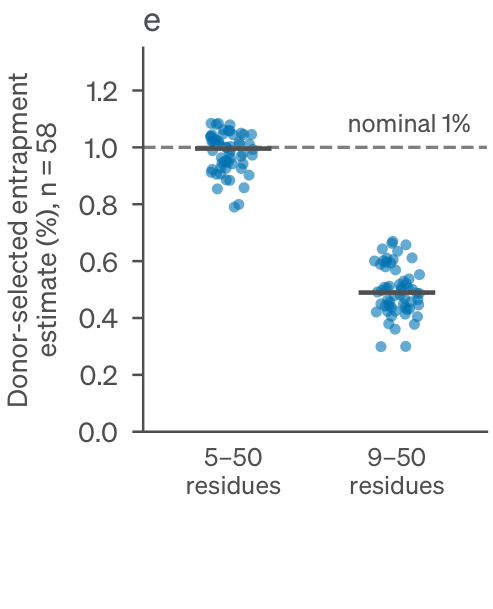

In [8]:
panels.panel_e(D, OUT)
print(panels.stat_e_entrapment(D))
panels.show(OUT / "panel_e.png")

## Checks and numbers

Pixel checks of panels b to e against the original producers' renders (`expected/`), a check that `expected/panel_e.png` is the stated crop of the copied v10 render, a check that `expected/Fig1_v28f.png` is the 300 dpi raster of the v28f composite PDF (the base page of the v30 build), a check that `expected/Fig1_v30.png` is the 300 dpi raster of `artwork/Figure1_v30.pdf`, the v30 funnel rebuilt from `artwork/` and compared with `expected/Fig1_v30.png`, and every recomputed number in `NUMBERS.tsv` order.

In [9]:
import csv, os, re
from tools.check_pixels import compare
CHK = UNIT / "checks"
if not os.environ.get("FASTALAKE_FONT_DIR") and not os.environ.get("FL_STYLE_DIR"):
    print("pixel checks SKIPPED: fonts absent")
else:
    E = UNIT / "expected"
    fig, axs, _ = panels._row(D)
    panels.crop_panel_e(E / "panels_bcde_row_v10.pdf", OUT / "panel_e_expected_rederived.png", fig, axs)
    jobs = [("panel_b", OUT / "panel_b.pdf", E / "panel_b.pdf"),
            ("panel_c", OUT / "panel_c.pdf", E / "panel_c.pdf"),
            ("panel_d", OUT / "panel_d.pdf", E / "panel_d.pdf"),
            ("panel_e", OUT / "panel_e.png", E / "panel_e.png"),
            ("panel_e_expected_derivation", OUT / "panel_e_expected_rederived.png", E / "panel_e.png"),
            ("Fig1_v28f", UNIT / "artwork" / "Figure1_v28f.pdf", E / "Fig1_v28f.png"),
            ("Fig1_v30", UNIT / "artwork" / "Figure1_v30.pdf", E / "Fig1_v30.png"),
            ("Fig1_v30_rebuild", panels.build_panel_a_funnel(UNIT, OUT), E / "Fig1_v30.png")]
    for name, new, exp in jobs:
        r = compare(new, exp, CHK / name, dpi=panels.DPI)
        print(f"{name:30s} {r['verdict']:14s} differing pixels {r.get('differing_pixels')}")
with open(UNIT / "NUMBERS.tsv", encoding="utf-8") as fh:
    rows = list(csv.DictReader(fh, delimiter="\t"))
V = panels.numbers(D)
for r in rows:
    key = re.search(r"\(key (\w+)\)", r["code"]).group(1)
    print(f"line {r['v28d_line']:>3}  printed {r['printed_value']:>12}  recomputed {V[key]!r}")

panel_b                        IDENTICAL      differing pixels 0
panel_c                        IDENTICAL      differing pixels 0


panel_d                        IDENTICAL      differing pixels 0
panel_e                        IDENTICAL      differing pixels 0


panel_e_expected_derivation    IDENTICAL      differing pixels 0


Fig1_v28f                      IDENTICAL      differing pixels 0


Fig1_v30                       IDENTICAL      differing pixels 0


Fig1_v30_rebuild               IDENTICAL      differing pixels 0
line  51  printed           58  recomputed 58
line  51  printed        233.5  recomputed 233.497702
line  51  printed       20,431  recomputed 20431
line  51  printed more than 10,000  recomputed 11428.598795947335
line  53  printed           58  recomputed 58
line  53  printed      250,000  recomputed 250197
line  53  printed           18  recomputed 18.007876
line  53  printed       25,000  recomputed 24560
line  53  printed          6.7  recomputed 6.671447
line  53  printed       12,600  recomputed 12606
line  53  printed  18,500-fold  recomputed 18522.743296842775
line  53  printed       29,700  recomputed 29663
line  55  printed          726  recomputed 726
line  55  printed       20,431  recomputed 20431
line  55  printed        3,100  recomputed 3057.0
line  55  printed       12,200  recomputed 12212.5
line  59  printed          8.1  recomputed 8.07609475951184
line  59  printed          8.9  recomputed 8.88370423